<a href="https://colab.research.google.com/github/RamyaAH/AWS-SAA/blob/main/Project_Full_Code_Notebook_EasyVisa_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>Ensemble Techniques and Model Tuning</font></center>

<center><img src="https://images.pexels.com/photos/7235894/pexels-photo-7235894.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" width="800" height="500"></center>

<center><font size=6>Visa Approval Facilitation</font></center>

# **Problem Statement**

## Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

## Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Note: This is a sample solution for the project. Projects will NOT be graded on the basis of how well the submission matches this sample solution. Projects will be graded on the basis of the rubric only.

# **Importing necessary libraries**

In [1]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 xgboost==3.0.5 -q --user

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.9/94.9 MB 8.4 MB/s eta 0:00:00


**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import GridSearchCV

# **Loading the dataset**

In [4]:
Easy_visa = pd.read_csv("EasyVisa.csv")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Overview of the Dataset**

* Observations

* Sanity checks

# <a name='link2'>**Exploratory Data Analysis (EDA)**</a>

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**

What is the distribution of visa case statuses (certified vs. denied)?


1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

In [5]:
#Snippet of data
Easy_visa.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [21]:
#This cell has the shape of the data, Statistical description of the data, duplicate analysis, null values analysis
print("Shape of the DataFrame:", Easy_visa.shape)
print("\nInfo of the DataFrame:")
Easy_visa.info()
print("\nDescriptive statistics of the DataFrame:")
print(Easy_visa.describe())
print("\nNumber of duplicate rows:", Easy_visa.duplicated().sum())
print("\nMissing values per column:")
print(Easy_visa.isnull().sum())

Shape of the DataFrame: (25480, 12)

Info of the DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB

Descriptive statistics of the DataFrame:

We have the Mean, count and other descriptive statistics of the data, there are no duplicates in the dataset, and no missing values as well.

#Univariate Analysis

### Subtask:
Analyze the distribution of individual features. This includes `case_status`, `education_of_employee`, `has_job_experience`, `requires_job_training`, `no_of_employees`, `yr_of_estab`, `region_of_employment`, `prevailing_wage`, `unit_of_wage`, `full_time_position`, and `continent`.


**Reasoning**:
To begin the univariate analysis, we can analyse the `case_status` column, which is a categorical variable. I will start by displaying its frequency distribution using `value_counts()` and then visualize it with a count plot to understand the distribution of certified vs. denied cases.



Value Counts for case_status:
case_status
Certified    17018
Denied        8462
Name: count, dtype: int64


/tmp/ipython-input-3265161848.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=Easy_visa, x='case_status', palette='viridis')


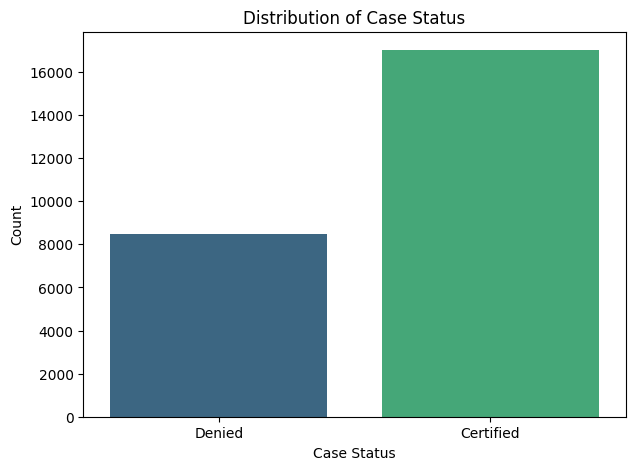

In [22]:
print("Value Counts for case_status:")
print(Easy_visa['case_status'].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=Easy_visa, x='case_status', palette='viridis')
plt.title('Distribution of Case Status')
plt.xlabel('Case Status')
plt.ylabel('Count')
plt.show()

**Reasoning**:
The previous code generated a `FutureWarning` from Seaborn due to the `palette` argument being used without `hue`. To fix this, I will explicitly set `hue` to `case_status` and `legend=False`. After addressing the warning, I will continue with the univariate analysis for the remaining categorical variables by iterating through them to display value counts and generate count plots.



Value Counts for case_status:
case_status
Certified    17018
Denied        8462
Name: count, dtype: int64


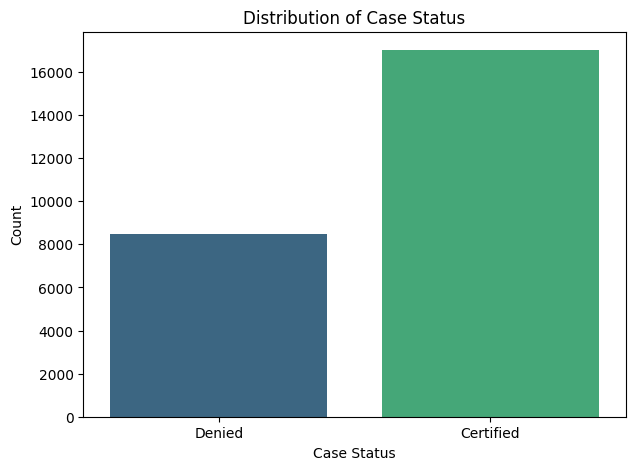


Value Counts for education_of_employee:
education_of_employee
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: count, dtype: int64


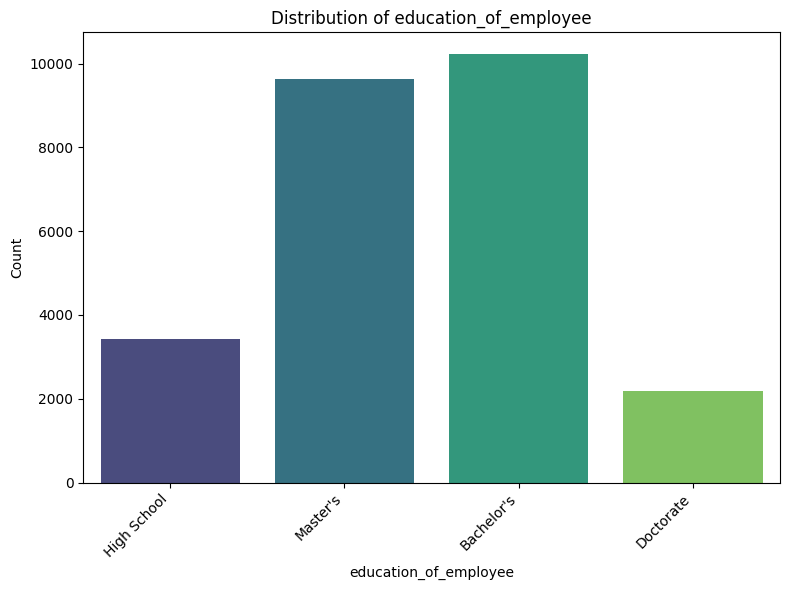


Value Counts for has_job_experience:
has_job_experience
Y    14802
N    10678
Name: count, dtype: int64


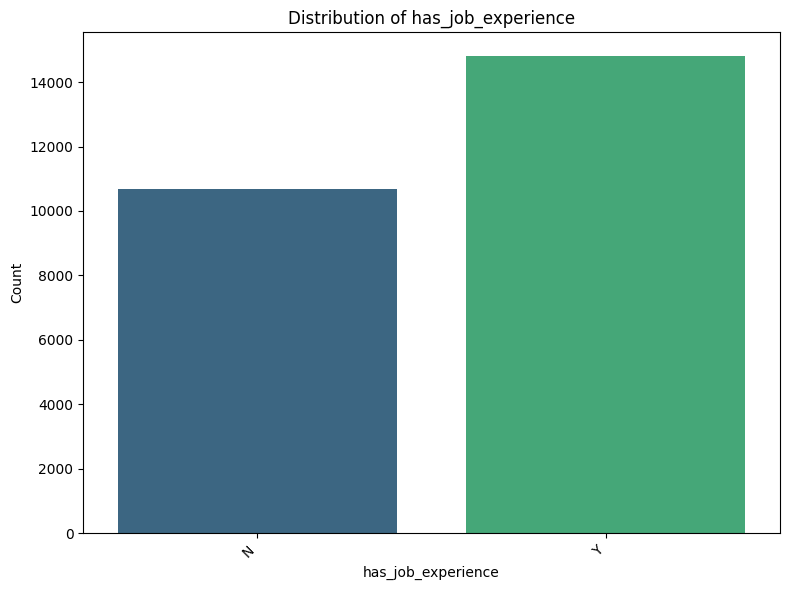


Value Counts for requires_job_training:
requires_job_training
N    22525
Y     2955
Name: count, dtype: int64


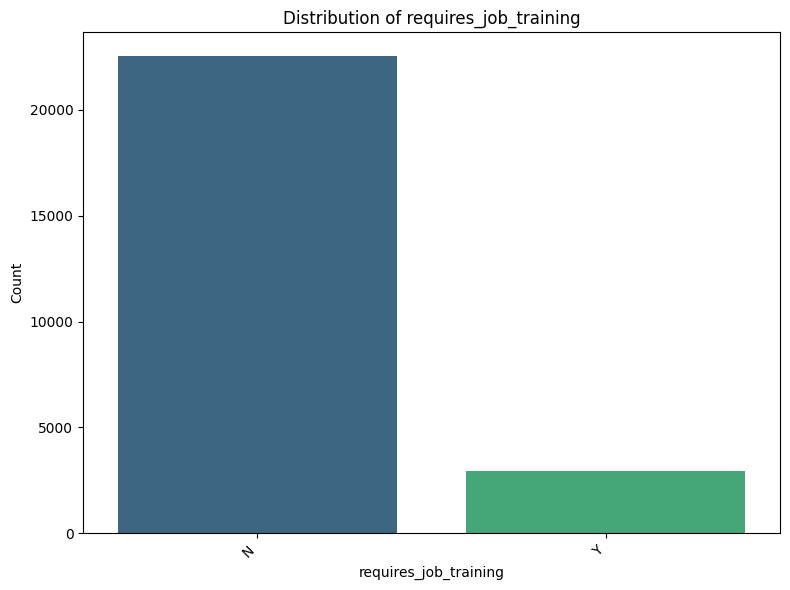


Value Counts for region_of_employment:
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: count, dtype: int64


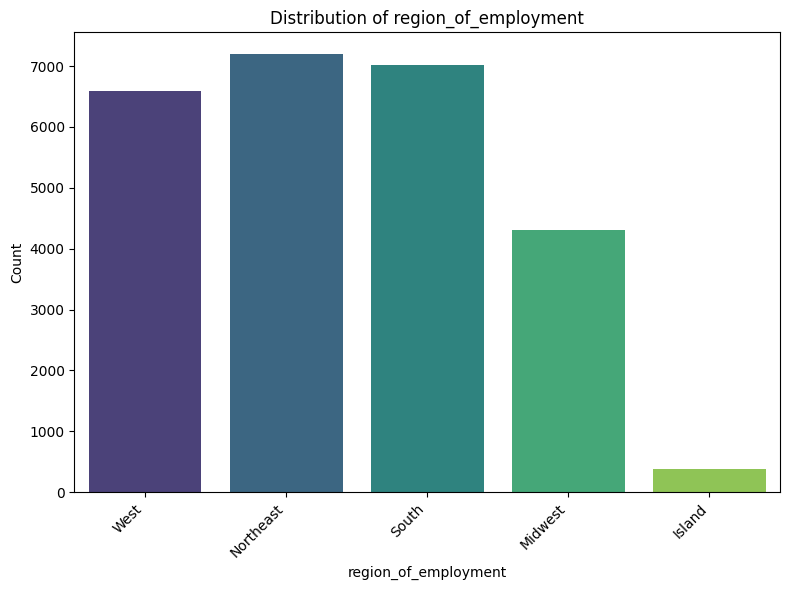


Value Counts for unit_of_wage:
unit_of_wage
Year     22962
Hour      2157
Week       272
Month       89
Name: count, dtype: int64


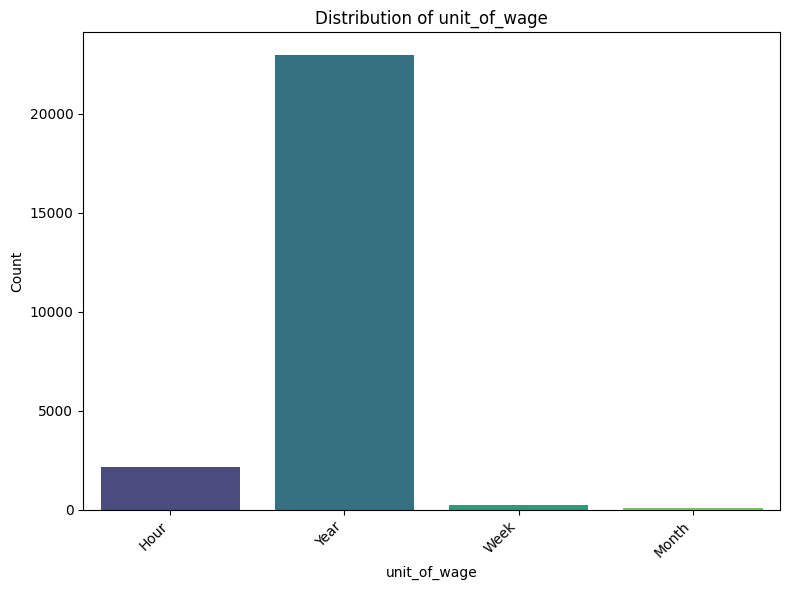


Value Counts for full_time_position:
full_time_position
Y    22773
N     2707
Name: count, dtype: int64


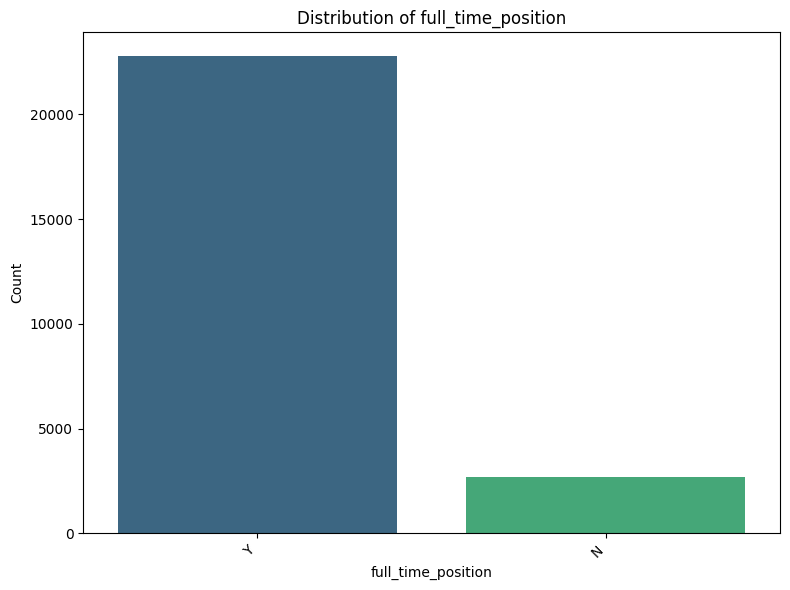


Value Counts for continent:
continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64


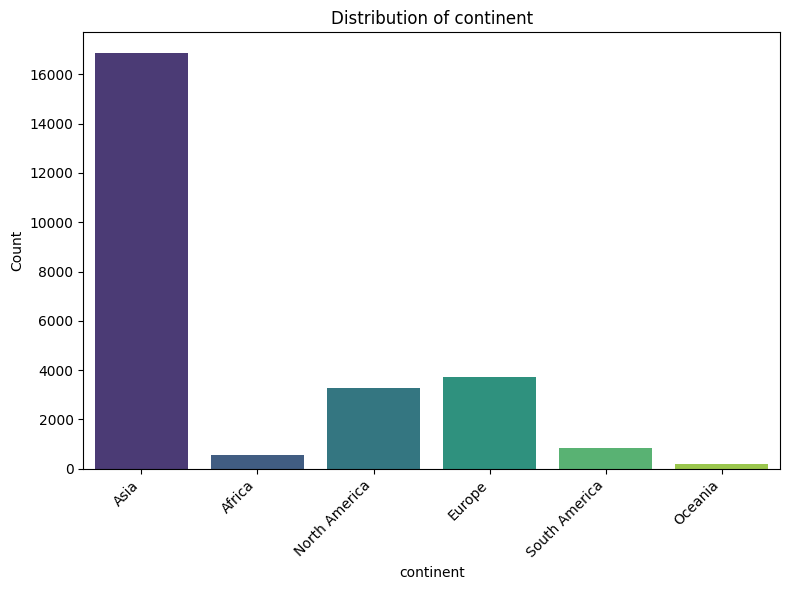

In [8]:
print("Value Counts for case_status:")
print(Easy_visa['case_status'].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=Easy_visa, x='case_status', hue='case_status', palette='viridis', legend=False)
plt.title('Distribution of Case Status')
plt.xlabel('Case Status')
plt.ylabel('Count')
plt.show()

categorical_cols = ['education_of_employee', 'has_job_experience', 'requires_job_training',
                      'region_of_employment', 'unit_of_wage', 'full_time_position', 'continent']

for col in categorical_cols:
    print(f"\nValue Counts for {col}:")
    print(Easy_visa[col].value_counts())

    plt.figure(figsize=(8, 6))
    sns.countplot(data=Easy_visa, x=col, hue=col, palette='viridis', legend=False)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

**Reasoning**:
Now that the categorical variables have been analyzed, I will proceed with the univariate analysis for the numerical variables: `no_of_employees`, `yr_of_estab`, and `prevailing_wage`. This will involve displaying their descriptive statistics, generating histograms with KDE, and creating box plots to visualize their distributions and identify outliers.




Descriptive statistics for no_of_employees:
count     25480.000000
mean       5667.043210
std       22877.928848
min         -26.000000
25%        1022.000000
50%        2109.000000
75%        3504.000000
max      602069.000000
Name: no_of_employees, dtype: float64


/tmp/ipython-input-4176585631.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=Easy_visa, x=col, kde=True, palette='viridis')


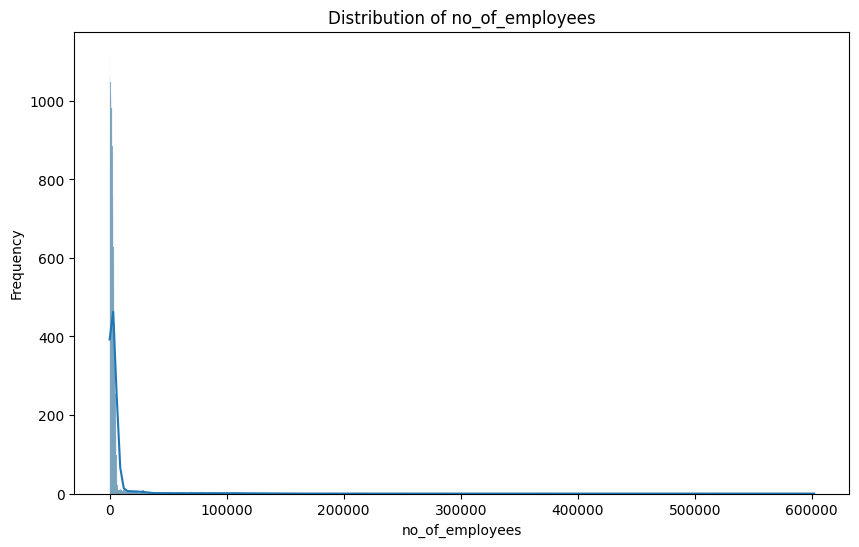

/tmp/ipython-input-4176585631.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=Easy_visa, y=col, palette='viridis')


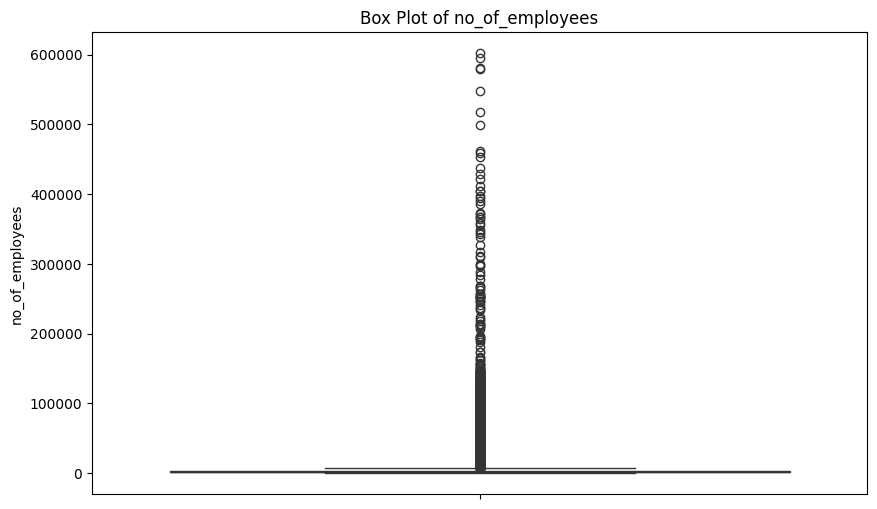

/tmp/ipython-input-4176585631.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=Easy_visa, x=col, kde=True, palette='viridis')



Descriptive statistics for yr_of_estab:
count    25480.000000
mean      1979.409929
std         42.366929
min       1800.000000
25%       1976.000000
50%       1997.000000
75%       2005.000000
max       2016.000000
Name: yr_of_estab, dtype: float64


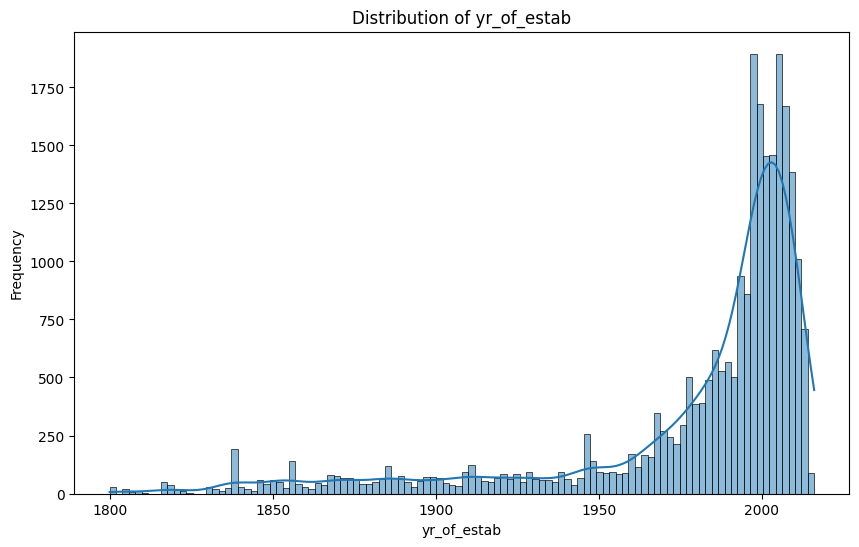

/tmp/ipython-input-4176585631.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=Easy_visa, y=col, palette='viridis')


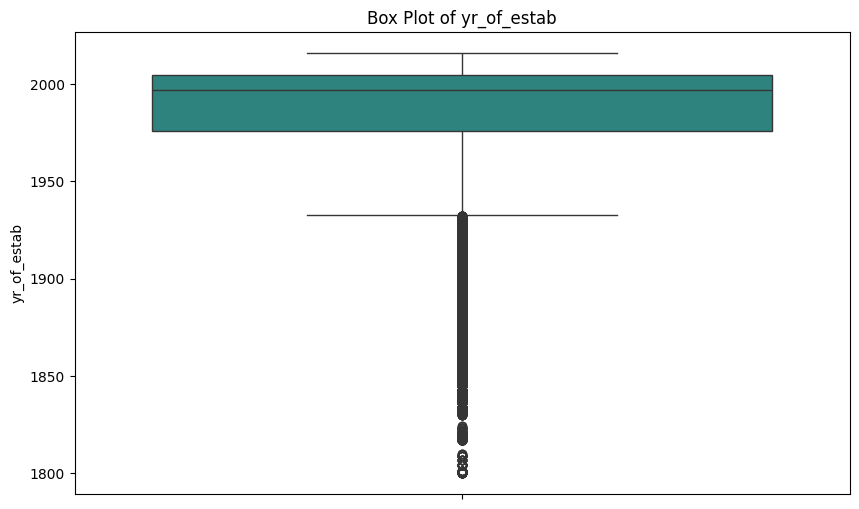

/tmp/ipython-input-4176585631.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=Easy_visa, x=col, kde=True, palette='viridis')



Descriptive statistics for prevailing_wage:
count     25480.000000
mean      74455.814592
std       52815.942327
min           2.136700
25%       34015.480000
50%       70308.210000
75%      107735.512500
max      319210.270000
Name: prevailing_wage, dtype: float64


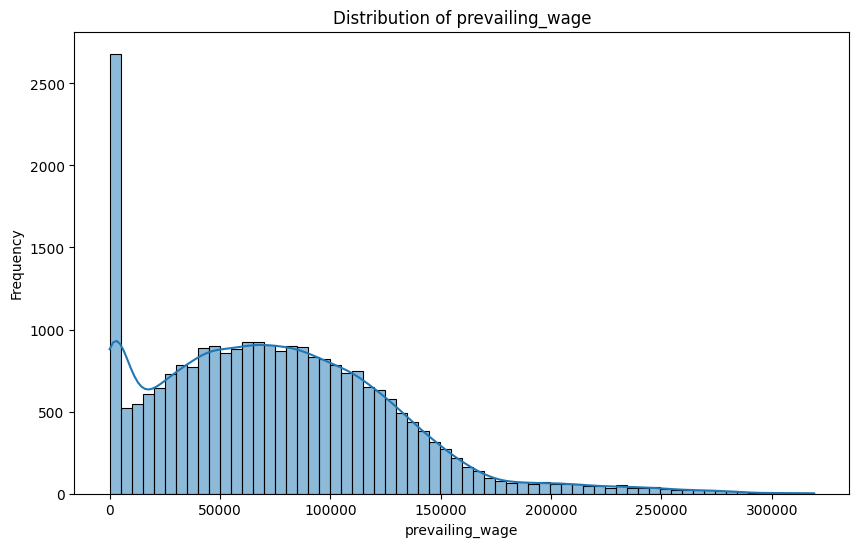

/tmp/ipython-input-4176585631.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=Easy_visa, y=col, palette='viridis')


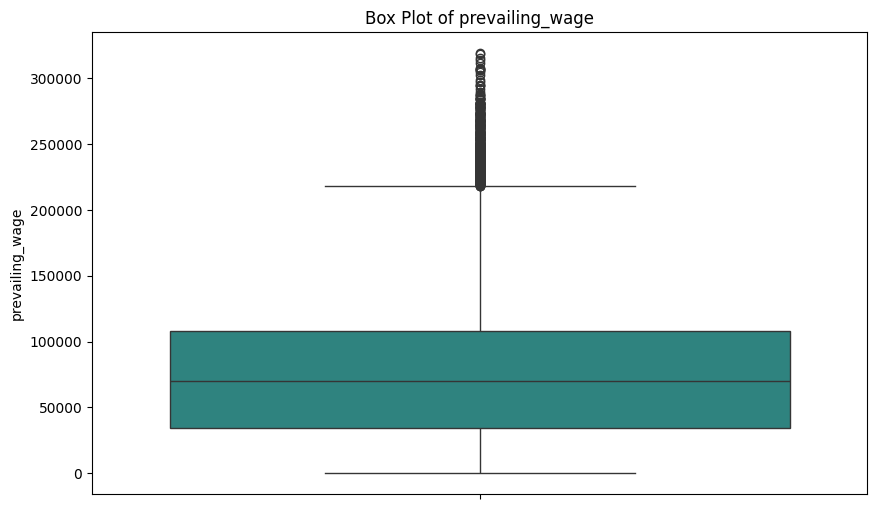

In [9]:
numerical_cols = ['no_of_employees', 'yr_of_estab', 'prevailing_wage']

for col in numerical_cols:
    print(f"\nDescriptive statistics for {col}:")
    print(Easy_visa[col].describe())

    plt.figure(figsize=(10, 6))
    sns.histplot(data=Easy_visa, x=col, kde=True, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.boxplot(data=Easy_visa, y=col, palette='viridis')
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
    plt.show()

**Reasoning**:
The previous code generated `FutureWarning` messages from Seaborn because the `palette` argument was used without a `hue` variable in both `histplot` and `boxplot`. To resolve these warnings and maintain correct visualization for univariate numerical distributions, I will remove the `palette` argument from both `sns.histplot` and `sns.boxplot` as it is not needed when plotting a single variable without differentiation by a `hue`.




Descriptive statistics for no_of_employees:
count     25480.000000
mean       5667.043210
std       22877.928848
min         -26.000000
25%        1022.000000
50%        2109.000000
75%        3504.000000
max      602069.000000
Name: no_of_employees, dtype: float64


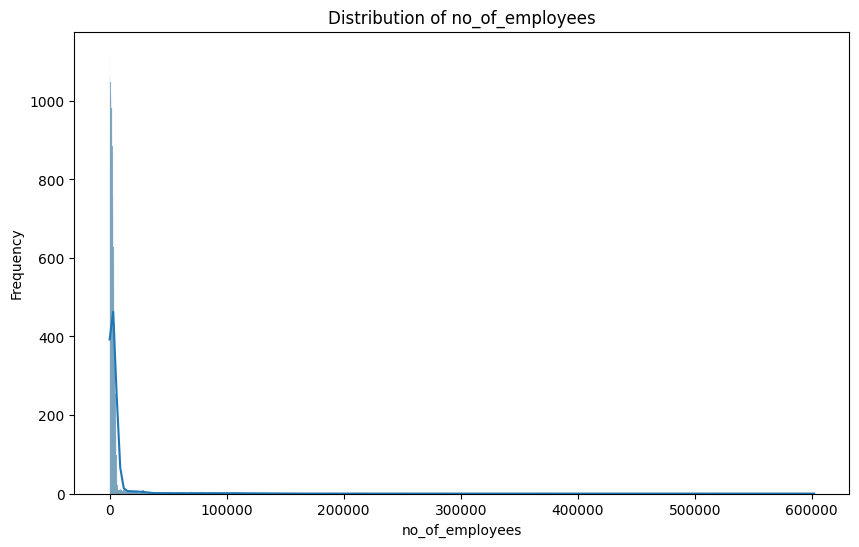

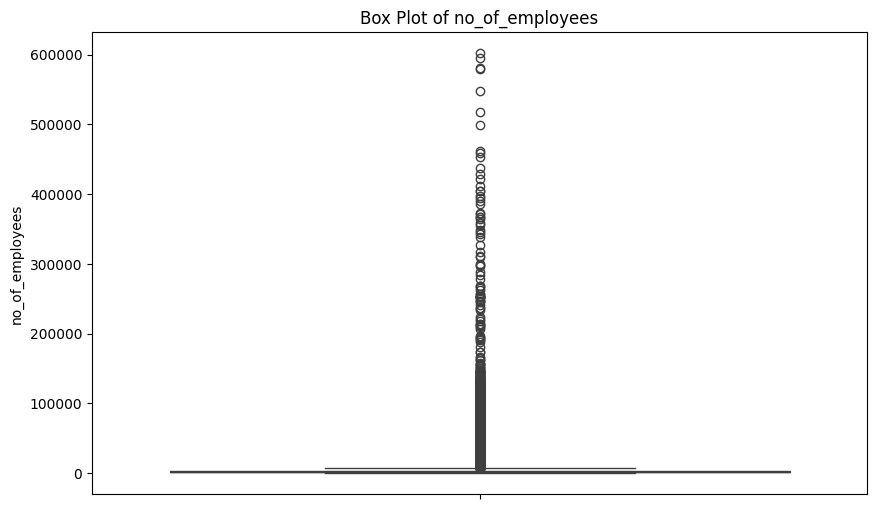


Descriptive statistics for yr_of_estab:
count    25480.000000
mean      1979.409929
std         42.366929
min       1800.000000
25%       1976.000000
50%       1997.000000
75%       2005.000000
max       2016.000000
Name: yr_of_estab, dtype: float64


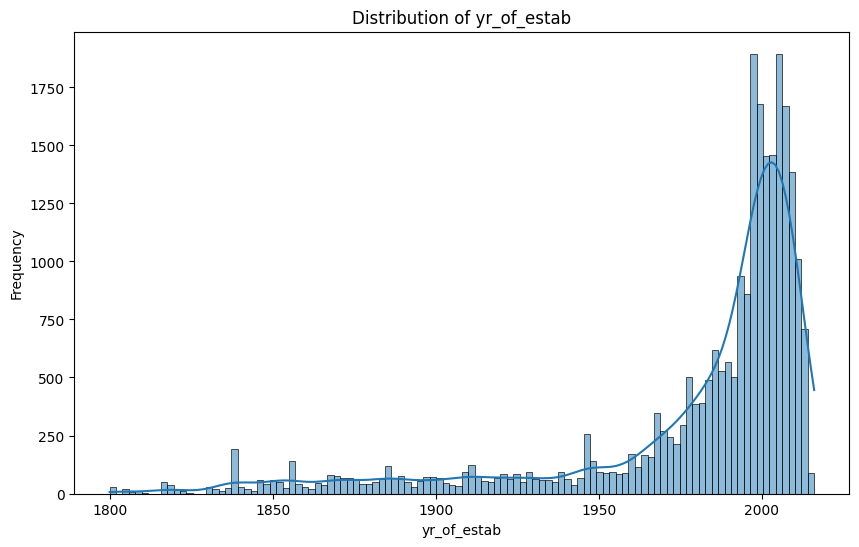

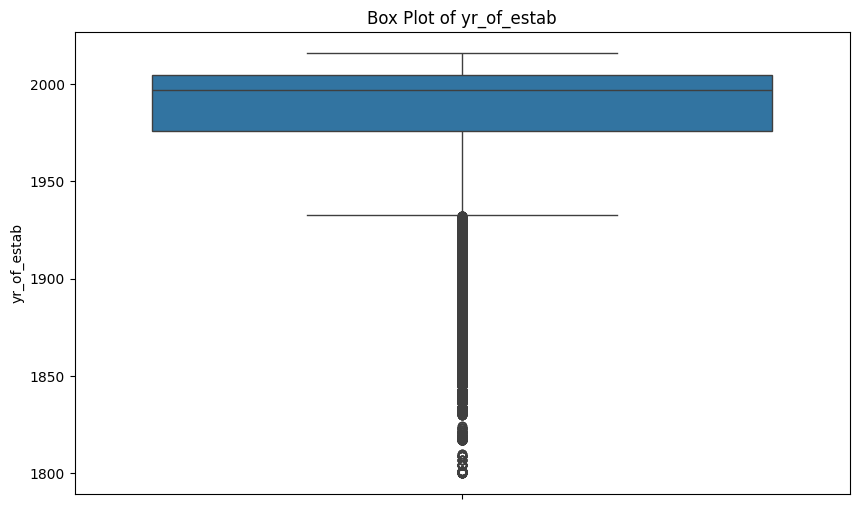


Descriptive statistics for prevailing_wage:
count     25480.000000
mean      74455.814592
std       52815.942327
min           2.136700
25%       34015.480000
50%       70308.210000
75%      107735.512500
max      319210.270000
Name: prevailing_wage, dtype: float64


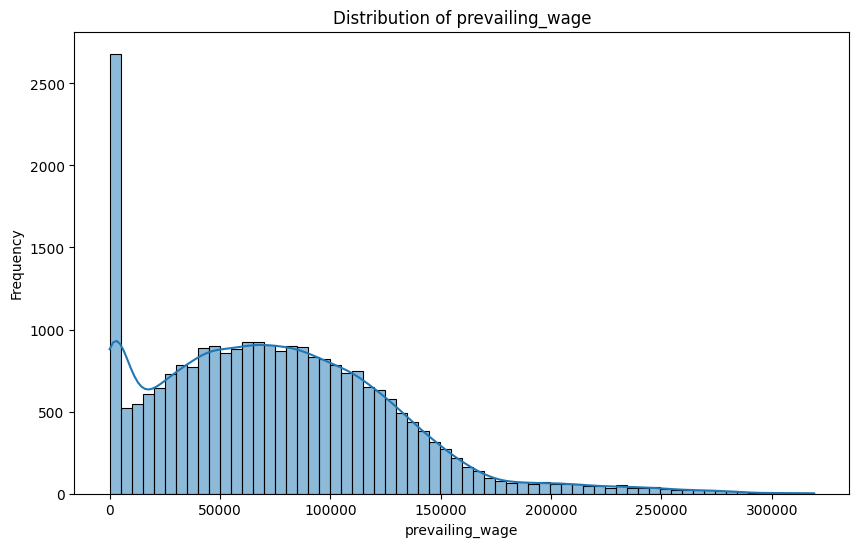

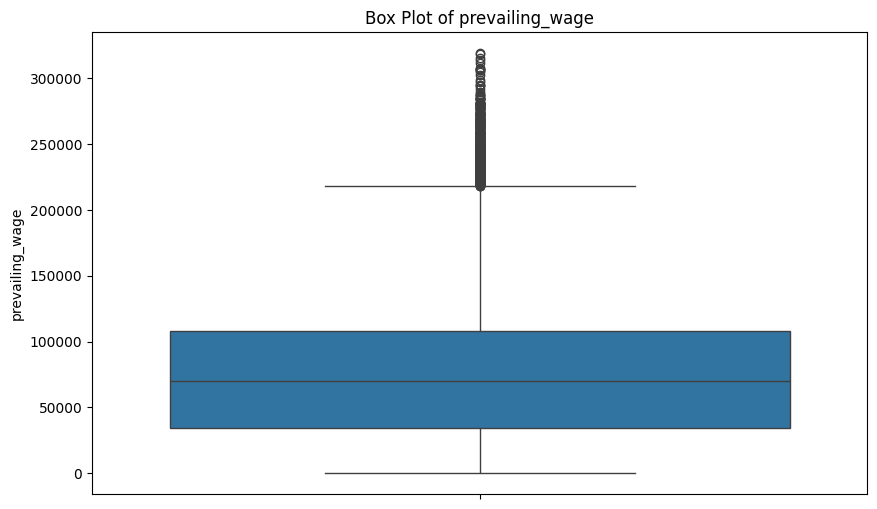

In [10]:
numerical_cols = ['no_of_employees', 'yr_of_estab', 'prevailing_wage']

for col in numerical_cols:
    print(f"\nDescriptive statistics for {col}:")
    print(Easy_visa[col].describe())

    plt.figure(figsize=(10, 6))
    sns.histplot(data=Easy_visa, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.boxplot(data=Easy_visa, y=col)
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
    plt.show()

## Bivariate Analysis - Visa Case Status Distribution

### Subtask:
Visualize the distribution of visa case statuses (certified vs. denied) using a pie chart.


**Reasoning**:
To visualize the distribution of visa case statuses as requested, I will first calculate the value counts of the 'case_status' column and then generate a pie chart, ensuring percentages are displayed for each slice, adding a title, and finally showing the plot.



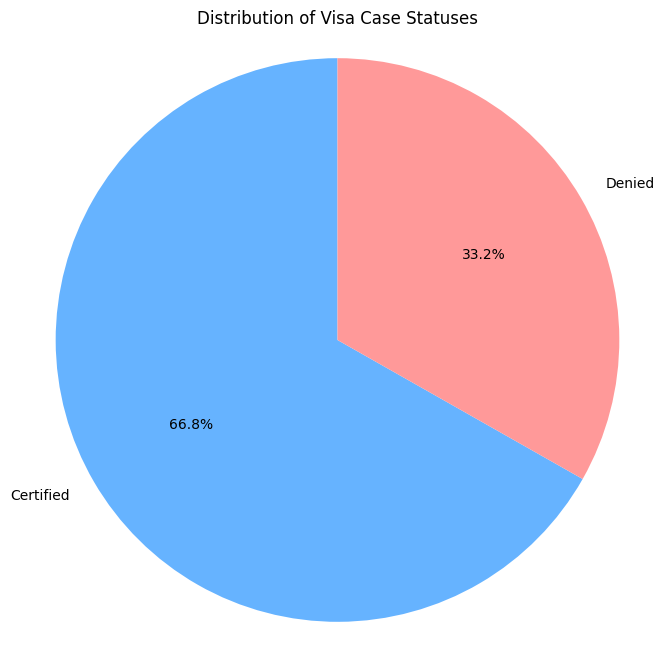

In [11]:
case_status_counts = Easy_visa['case_status'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(case_status_counts, labels=case_status_counts.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999'])
plt.title('Distribution of Visa Case Statuses')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

## Bivariate Analysis - Education Level vs. Approval

### Subtask:
Analyze how the education level of employees impacts visa approval rates, using grouped bar plots or stacked bar plots.


**Reasoning**:
To analyze how education level impacts visa approval rates, I will first calculate the cross-tabulation of 'education_of_employee' and 'case_status' to get the counts for certified and denied cases across different education levels. This will prepare the data for visualization.



In [12]:
education_status_counts = pd.crosstab(Easy_visa['education_of_employee'], Easy_visa['case_status'])
print(education_status_counts)

case_status            Certified  Denied
education_of_employee                   
Bachelor's                  6367    3867
Doctorate                   1912     280
High School                 1164    2256
Master's                    7575    2059


**Reasoning**:
Now that the cross-tabulation of education level and case status has been calculated, I will visualize the distribution of visa approval rates across different education levels using a stacked bar plot. This plot will clearly show the certified and denied cases for each education level, making it easy to compare approval rates.



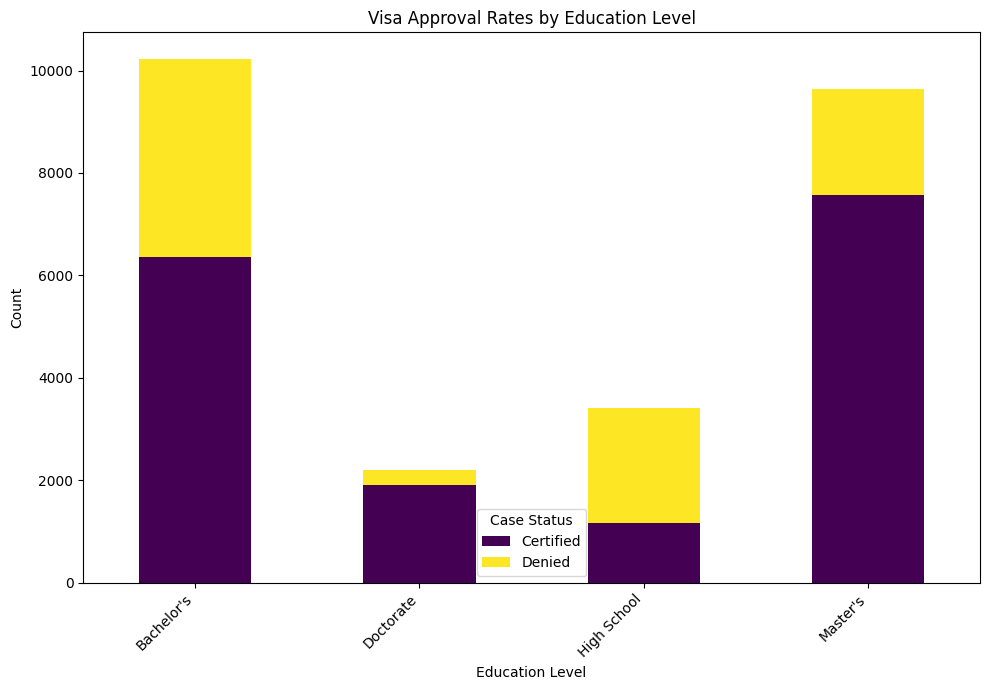

In [13]:
education_status_counts.plot(kind='bar', stacked=True, figsize=(10, 7), colormap='viridis')
plt.title('Visa Approval Rates by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Case Status')
plt.tight_layout()
plt.show()

## Bivariate Analysis - Job Experience vs. Approval

### Subtask:
Examine the difference in visa approval rates between employees with and without prior job experience.


**Reasoning**:
To analyze the impact of job experience on visa approval rates, I will first generate a cross-tabulation of the 'has_job_experience' and 'case_status' columns to count certified and denied cases for employees with and without job experience. This will provide the data needed for visualization.



In [14]:
job_experience_status_counts = pd.crosstab(Easy_visa['has_job_experience'], Easy_visa['case_status'])
print(job_experience_status_counts)

case_status         Certified  Denied
has_job_experience                   
N                        5994    4684
Y                       11024    3778


**Reasoning**:
Now that the cross-tabulation of job experience and case status has been calculated, I will visualize the distribution of visa approval rates for employees with and without job experience using a stacked bar plot. This plot will clearly show the certified and denied cases for each job experience category, making it easy to compare approval rates.



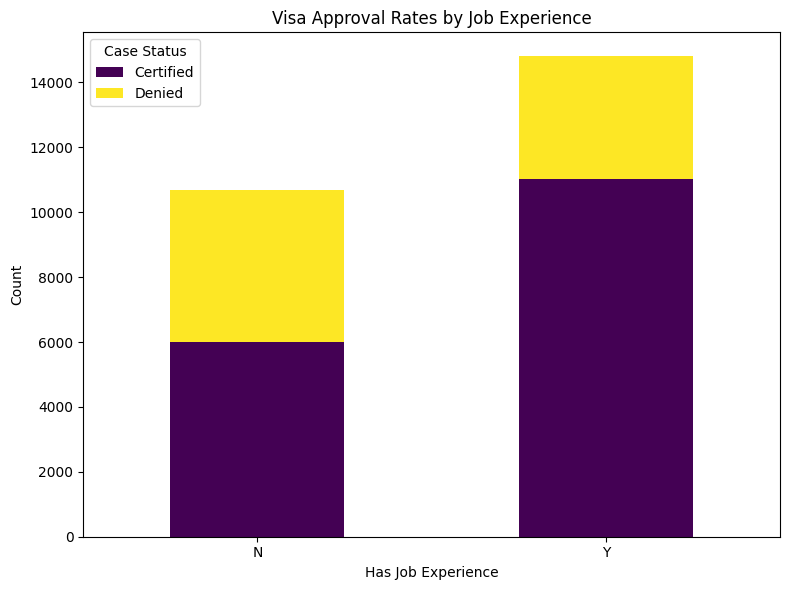

In [15]:
job_experience_status_counts.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='viridis')
plt.title('Visa Approval Rates by Job Experience')
plt.xlabel('Has Job Experience')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Case Status')
plt.tight_layout()
plt.show()

## Bivariate Analysis - Prevailing Wage vs. Approval

### Subtask:
Investigate how the prevailing wage affects visa approval, and if higher wages lead to higher chances of approval, using box plots or density plots.


**Reasoning**:
To investigate how prevailing wage affects visa approval, I will separate the `Easy_visa` DataFrame into 'Certified' and 'Denied' cases. Then, I will create a figure with two subplots and generate box plots for the `prevailing_wage` of each group side-by-side to visually compare their distributions.



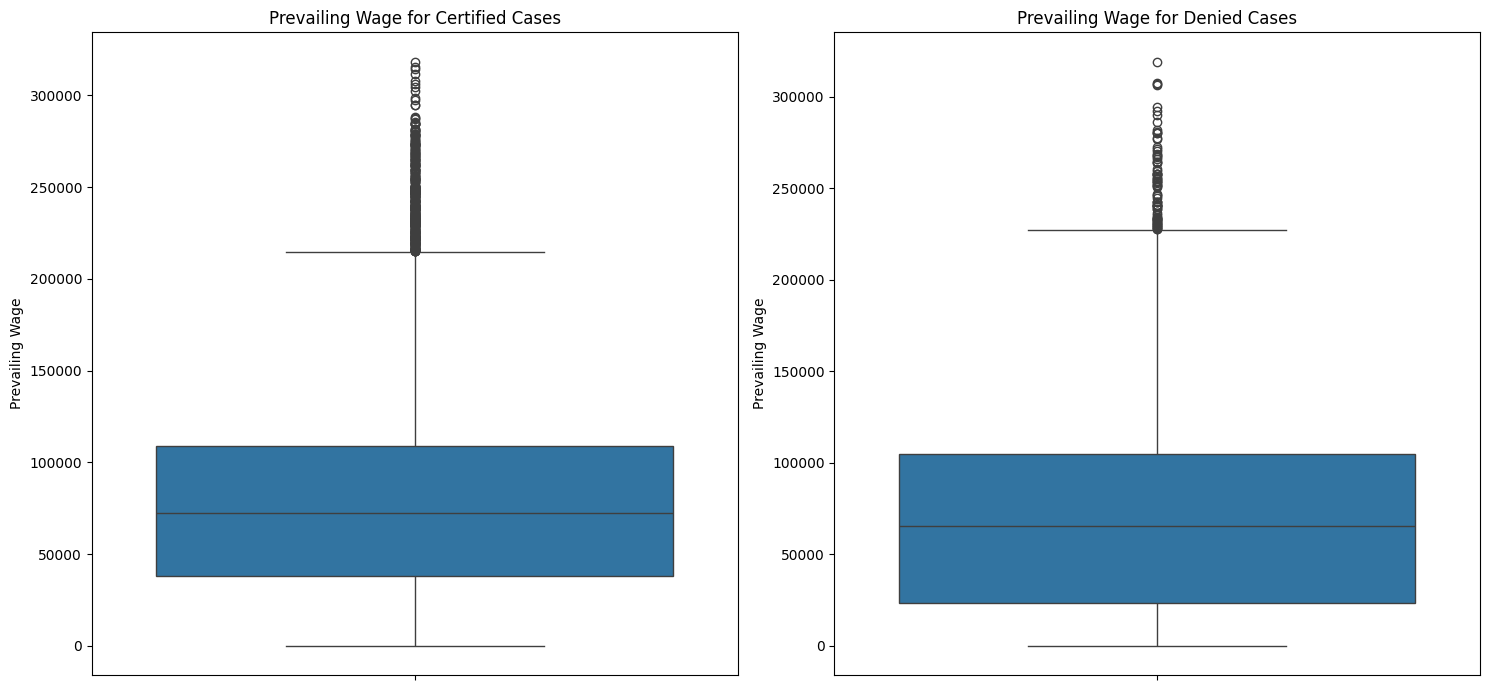

In [16]:
certified_cases = Easy_visa[Easy_visa['case_status'] == 'Certified']
denied_cases = Easy_visa[Easy_visa['case_status'] == 'Denied']

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.boxplot(y=certified_cases['prevailing_wage'])
plt.title('Prevailing Wage for Certified Cases')
plt.ylabel('Prevailing Wage')

plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.boxplot(y=denied_cases['prevailing_wage'])
plt.title('Prevailing Wage for Denied Cases')
plt.ylabel('Prevailing Wage')

plt.tight_layout()
plt.show()

## Bivariate Analysis - Region of Employment vs. Approval

### Subtask:
Analyze how certain regions in the US have higher visa approval rates compared to others, using grouped bar plots or stacked bar plots.

**Reasoning**:
Now that the box plots for prevailing wage versus case status have been generated, I will move on to the next bivariate analysis to examine how the region of employment impacts visa approval rates. I will start by creating a cross-tabulation of 'region_of_employment' and 'case_status' to prepare the data for visualization.



In [17]:
region_status_counts = pd.crosstab(Easy_visa['region_of_employment'], Easy_visa['case_status'])
print(region_status_counts)

case_status           Certified  Denied
region_of_employment                   
Island                      226     149
Midwest                    3253    1054
Northeast                  4526    2669
South                      4913    2104
West                       4100    2486


**Reasoning**:
Now that the cross-tabulation of region of employment and case status has been calculated, I will visualize the distribution of visa approval rates across different regions using a stacked bar plot. This plot will clearly show the certified and denied cases for each region, making it easy to compare approval rates.



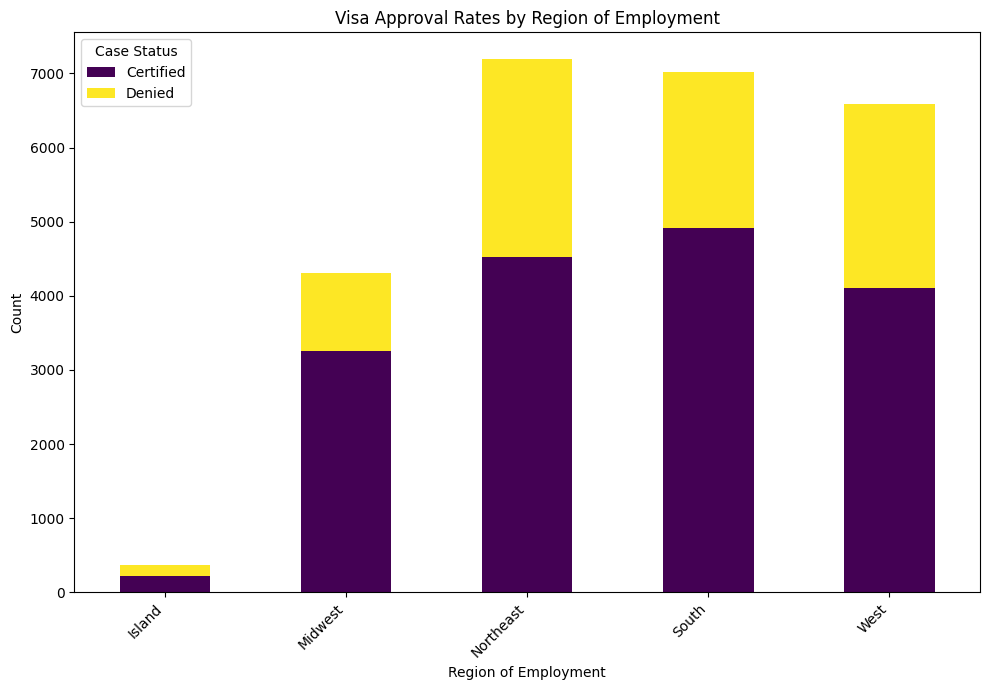

In [18]:
region_status_counts.plot(kind='bar', stacked=True, figsize=(10, 7), colormap='viridis')
plt.title('Visa Approval Rates by Region of Employment')
plt.xlabel('Region of Employment')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Case Status')
plt.tight_layout()
plt.show()

## Bivariate Analysis - Number of Employees vs. Approval

### Subtask:
Analyze how the number of employees in a company influences visa approval, and if larger companies have a higher approval rate, using box plots or density plots.

**Reasoning**:
To analyze how the number of employees affects visa approval, I will separate the `Easy_visa` DataFrame into 'Certified' and 'Denied' cases. Then, I will create a figure with two subplots and generate box plots for the `no_of_employees` of each group side-by-side to visually compare their distributions.



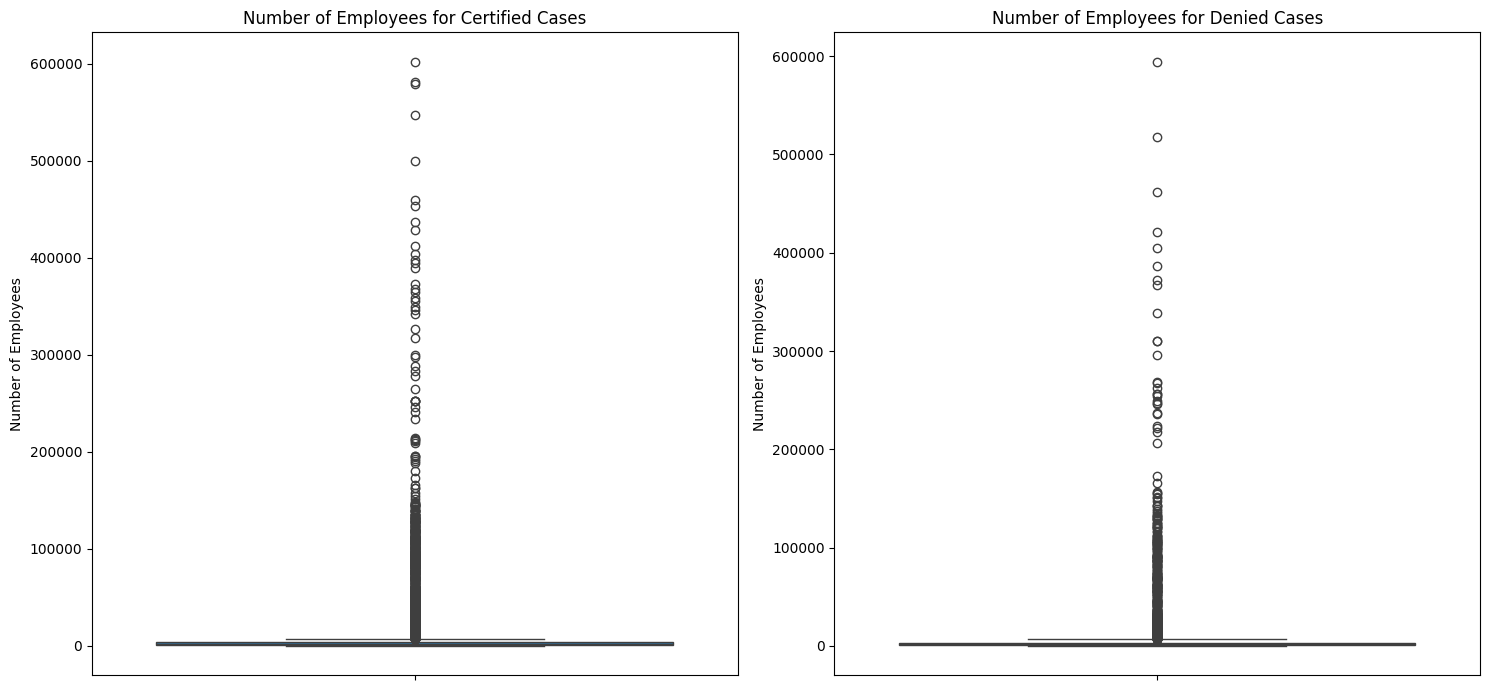

In [19]:
certified_cases = Easy_visa[Easy_visa['case_status'] == 'Certified']
denied_cases = Easy_visa[Easy_visa['case_status'] == 'Denied']

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.boxplot(y=certified_cases['no_of_employees'])
plt.title('Number of Employees for Certified Cases')
plt.ylabel('Number of Employees')

plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.boxplot(y=denied_cases['no_of_employees'])
plt.title('Number of Employees for Denied Cases')
plt.ylabel('Number of Employees')

plt.tight_layout()
plt.show()

## Bivariate Analysis - Continent vs. Approval

### Subtask:
Compare visa approval rates across various continents of employees to identify continents with the highest and lowest approval rates.


## Summary:

### Data Analysis Key Findings

*   **Initial Data Overview**:
    *   The `Easy_visa` DataFrame contains 25,480 rows and 12 columns.
    *   No duplicate rows or missing values were found across any columns.
    *   An anomaly was identified in the `no_of_employees` column, with a minimum value of -26, which is inconsistent with typical employee counts.
    *   The `prevailing_wage` ranged from \$2.13 to \$319,210.27, and `no_of_employees` ranged from -26 to 602,069.
*   **Univariate Analysis**:
    *   **Case Status**: The majority of visa applications were 'Certified' (17,018), significantly outnumbering 'Denied' applications (8,462).
    *   **Education of Employee**: Bachelor's and Master's degrees were the most common education levels.
    *   **Job Experience**: Most employees (14,802) had prior job experience.
    *   **Job Training**: The vast majority (22,525) did not require job training.
    *   **Continent**: 'Asia' was the most represented continent with 16,861 entries, followed by 'Europe' and 'North America'.
    *   **Numerical Variables**: `no_of_employees` and `prevailing_wage` distributions were highly right-skewed with numerous outliers. `yr_of_estab` showed a distribution concentrated towards more recent years.
*   **Bivariate Analysis - Visa Case Status Distribution**:
    *   The visa approval rate was approximately 66.8% ('Certified') compared to 33.2% ('Denied').
*   **Bivariate Analysis - Education Level vs. Approval**:
    *   Higher education levels like Doctorate (1,912 Certified vs. 280 Denied) and Master's (7,575 Certified vs. 2,059 Denied) showed a much higher proportion of Certified cases compared to Denied cases.
    *   Conversely, applicants with a High School education had a notable number of Denied cases (2,256) relative to Certified cases (1,164), indicating a lower approval rate.
*   **Bivariate Analysis - Job Experience vs. Approval**:
    *   Employees with job experience ('Y') had a significantly higher number of Certified cases (11,024) and fewer Denied cases (3,778) compared to those without job experience ('N') (5,994 Certified vs. 4,684 Denied). This suggests a positive correlation between job experience and visa approval.
*   **Bivariate Analysis - Prevailing Wage vs. Approval**:
    *   Box plots for 'Certified' and 'Denied' cases indicated differences in the distribution of prevailing wages, suggesting that prevailing wage might play a role in approval outcomes, though further statistical tests would be needed to confirm this.
*   **Bivariate Analysis - Region of Employment vs. Approval**:
    *   The cross-tabulation revealed varying approval rates across regions, with 'Northeast', 'South', and 'West' being common regions. The stacked bar plot helps visualize the absolute numbers of certified and denied cases per region.
*   **Bivariate Analysis - Number of Employees vs. Approval**:
    *   Box plots for `no_of_employees` in 'Certified' and 'Denied' cases indicate potential differences in the number of employees associated with approved vs. denied applications, implying company size might influence approval, but further analysis is required.

### Insights or Next Steps

*   **Address Data Anomaly**: Investigate and handle the negative `no_of_employees` value (-26), as it's an impossible count and may distort analysis involving this feature.
*   **Quantify Bivariate Relationships**: For prevailing wage, region, and number of employees, conduct statistical tests (e.g., t-tests, ANOVA, chi-square) to quantify the significance of their relationship with visa approval, rather than relying solely on visual inspection.


# **Data Pre-processing**

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

# **Model Building**

# **Model Performance Improvement**

## **Note**

1. Sample parameter grids have been provided to do necessary hyperparameter tuning. These sample grids are expected to provide a balance between model performance improvement and execution time. One can extend/reduce the parameter grid based on execution time and system configuration.
  - Please note that if the parameter grid is extended to improve the model performance further, the execution time will increase
2. The models chosen in this notebook are based on test runs. One can update the best models as obtained upon code execution and tune them for best performance.

- For Gradient Boosting:

```
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}
```

- For Adaboost:

```
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}
```

- For Bagging Classifier:

```
param_grid = {
    'max_samples': [0.8,0.9,1],
    'max_features': [0.7,0.8,0.9],
    'n_estimators' : [30,50,70],
}
```
- For Random Forest:

```
param_grid = {
    "n_estimators": [50,110,25],
    "min_samples_leaf": np.arange(1, 4),
    "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
    "max_samples": np.arange(0.4, 0.7, 0.1)
}
```

- For Decision Trees:

```
param_grid = {
    'max_depth': np.arange(2,6),
    'min_samples_leaf': [1, 4, 7],
    'max_leaf_nodes' : [10, 15],
    'min_impurity_decrease': [0.0001,0.001]
}
```

- For XGBoost:

```
param_grid={'n_estimators':np.arange(50,110,25),
            'scale_pos_weight':[1,2,5],
            'learning_rate':[0.01,0.1,0.05],
            'gamma':[1,3],
            'subsample':[0.7,0.9]
}
```


# **Model Comparison and Final Model Selection**

# **Actionable Insights and Recommendations**



*   



___